# Device/Variant Overlay Plot for One-Device Latent Heteroscedastic GP

装置ごとのMCMC出力に加え、`*_ADVI_tstudent.csv` などの推論variantも同じ形式で読み込み、prediction interval・sigma/scale・summaryを比較します。

この notebook では MCMC や GP fitting は実行しません。


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import numpy as np
import pandas as pd


## 1. Settings

比較したい装置と出力先を指定します。存在しないCSVはスキップします。

In [2]:
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "2_Program":
    PROJECT_ROOT = PROJECT_ROOT.parent

OUTPUT_DIR = PROJECT_ROOT / "0_Data" / "3_Figure" / "Mineral_Mode_Relative_Error/"
FIGURE_DIR = OUTPUT_DIR
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Each entry can point to an ordinary device output such as "LAB-PXRD" or
# to a variant output such as "LAB-PXRD_ADVI_tstudent".
# `base_device` is used for observed/model-data fallback and color grouping.
OVERLAY_VARIANTS = [
    # {"label": "EPMA MCMC", "safe_device": "EPMA", "base_device": "EPMA", "variant": "MCMC Normal"},
    {"label": "EPMA ADVI-t", "safe_device": "EPMA_ADVI_tstudent", "base_device": "EPMA", "variant": "ADVI Student-t"},
    # {"label": "SR-PXRD MCMC", "safe_device": "SR-PXRD", "base_device": "SR-PXRD", "variant": "MCMC Normal"},
    {"label": "SR-PXRD ADVI-t", "safe_device": "SR-PXRD_ADVI_tstudent", "base_device": "SR-PXRD", "variant": "ADVI Student-t"},
    # {"label": "LAB-PXRD MCMC", "safe_device": "LAB-PXRD", "base_device": "LAB-PXRD", "variant": "MCMC Normal"},
    {"label": "LAB-PXRD ADVI-t", "safe_device": "LAB-PXRD_ADVI_tstudent", "base_device": "LAB-PXRD", "variant": "ADVI Student-t"},
    # {"label": "LAB-PXRD ADVI", "safe_device": "LAB-PXRD_ADVI", "base_device": "LAB-PXRD", "variant": "ADVI Normal"},
]

OVERLAY_DEVICES = [entry["label"] for entry in OVERLAY_VARIANTS]
OBSERVED_BASE_DEVICES = ["EPMA", "SR-PXRD", "LAB-PXRD"]

BASE_DEVICE_COLORS = {
    "SR-PXRD": "#FF7F50",
    "LAB-PXRD": "#FFC107",
    "EPMA": "#9D5B8B",
}
VARIANT_LINESTYLES = {
    "MCMC Normal": "-",
    "ADVI Normal": ":",
    "ADVI Student-t": "--",
}
VARIANT_ALPHA = {
    "MCMC Normal": 0.16,
    "ADVI Normal": 0.10,
    "ADVI Student-t": 0.12,
}

# Backward-compatible color lookup by plotted label.
INSTRUMENT_COLORS = {
    entry["label"]: BASE_DEVICE_COLORS.get(entry["base_device"], "C0")
    for entry in OVERLAY_VARIANTS
}

PLOT_MEAN_ERROR = False
PLOT_PREDICTIVE_MEDIAN = True
PLOT_95_INTERVAL = True
PLOT_50_INTERVAL = False

OUTPUT_PREFIX = "device_overlay_ADVI_compare"

OUTPUT_DIR, FIGURE_DIR


(PosixPath('/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error'),
 PosixPath('/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error'))

## 2. Load Device/Variant Predictions and Summaries

通常の装置名CSVに加え、`LAB-PXRD_ADVI_tstudent` のようなsuffix付きCSVを読み込みます。存在しないvariantはスキップします。


In [3]:
def safe_name(name):
    return str(name).replace("/", "-").replace(" ", "_")


def prediction_path_for_safe_device(output_dir, safe_device):
    return output_dir / f"one_device_latent_hgp_real_data_predictions_{safe_name(safe_device)}.csv"


def summary_path_for_safe_device(output_dir, safe_device):
    return output_dir / f"one_device_latent_hgp_real_data_mcmc_summary_{safe_name(safe_device)}.csv"


def model_data_path_for_safe_device(output_dir, safe_device):
    return output_dir / f"one_device_latent_hgp_real_data_model_data_{safe_name(safe_device)}.csv"


def get_variant_meta(label):
    for entry in OVERLAY_VARIANTS:
        if entry["label"] == label:
            return entry
    return {"label": label, "safe_device": label, "base_device": label, "variant": "unknown"}


def load_device_predictions(output_dir, variants):
    predictions = {}
    summaries = {}
    missing_predictions = []
    missing_summaries = []

    for entry in variants:
        label = entry["label"]
        safe_device = entry["safe_device"]
        path = prediction_path_for_safe_device(output_dir, safe_device)
        if not path.exists():
            missing_predictions.append((label, path))
            continue

        pred = pd.read_csv(path)
        if "device" not in pred.columns:
            pred.insert(0, "device", entry["base_device"])
        pred["plot_label"] = label
        pred["base_device"] = entry["base_device"]
        pred["inference_variant"] = entry["variant"]
        pred["source_csv"] = str(path)
        predictions[label] = pred

        summary_path = summary_path_for_safe_device(output_dir, safe_device)
        if summary_path.exists():
            summary = pd.read_csv(summary_path, index_col=0)
            summary.insert(0, "plot_label", label)
            summary.insert(1, "base_device", entry["base_device"])
            summary.insert(2, "inference_variant", entry["variant"])
            summary.insert(3, "source_csv", str(summary_path))
            summaries[label] = summary
        else:
            missing_summaries.append((label, summary_path))

    print("Loaded prediction variants:", list(predictions.keys()))
    if missing_predictions:
        print("Missing prediction CSVs:")
        for label, path in missing_predictions:
            print(f"  {label}: {path}")
    if missing_summaries:
        print("Missing summary CSVs:")
        for label, path in missing_summaries:
            print(f"  {label}: {path}")

    if not predictions:
        raise FileNotFoundError("No prediction CSVs were found. Run the model notebooks first.")

    return predictions, summaries


predictions_by_device, summaries_by_variant = load_device_predictions(OUTPUT_DIR, OVERLAY_VARIANTS)

loaded_summary = []
for label, pred_i in predictions_by_device.items():
    meta = get_variant_meta(label)
    loaded_summary.append({
        "label": label,
        "base_device": meta["base_device"],
        "variant": meta["variant"],
        "n_grid": len(pred_i),
        "x_min": pred_i["ref_wt"].min(),
        "x_max": pred_i["ref_wt"].max(),
        "source_csv": pred_i["source_csv"].iloc[0],
    })

loaded_summary_df = pd.DataFrame(loaded_summary)
display(loaded_summary_df)

if summaries_by_variant:
    summary_compare_df = pd.concat(summaries_by_variant.values(), axis=0)
    display(summary_compare_df)
else:
    summary_compare_df = pd.DataFrame()


Loaded prediction variants: ['EPMA ADVI-t', 'SR-PXRD ADVI-t', 'LAB-PXRD ADVI-t']


,label,base_device,variant,n_grid,x_min,x_max,source_csv
0,EPMA ADVI-t,EPMA,ADVI Student-t,100,0.075,72.733,/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_D...
1,SR-PXRD ADVI-t,SR-PXRD,ADVI Student-t,100,0.064,75.060,/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_D...
2,LAB-PXRD ADVI-t,LAB-PXRD,ADVI Student-t,100,0.064,75.060,/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_D...


,plot_label,base_device,inference_variant,source_csv,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
ell_f,EPMA ADVI-t,EPMA,ADVI Student-t,/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_D...,1.481,0.245,1.045,1.937,0.004,0.003,3927.098,3918.329,NaN
eta_f,EPMA ADVI-t,EPMA,ADVI Student-t,/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_D...,27.049,3.893,20.143,34.455,0.060,0.046,4171.231,3962.463,NaN
ell_h,EPMA ADVI-t,EPMA,ADVI Student-t,/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_D...,0.897,0.142,0.632,1.157,0.002,0.002,3955.655,3702.717,NaN
eta_h,EPMA ADVI-t,EPMA,ADVI Student-t,/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_D...,0.632,0.112,0.424,0.833,0.002,0.001,4032.986,3999.501,NaN
h0,EPMA ADVI-t,EPMA,ADVI Student-t,/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_D...,2.996,0.106,2.790,3.190,0.002,0.001,3973.167,4040.478,NaN
ell_f,SR-PXRD ADVI-t,SR-PXRD,ADVI Student-t,/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_D...,1.028,0.171,0.724,1.354,0.003,0.002,4045.631,3881.357,NaN
eta_f,SR-PXRD ADVI-t,SR-PXRD,ADVI Student-t,/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_D...,6.131,0.520,5.168,7.099,0.008,0.006,3813.241,3649.473,NaN
ell_h,SR-PXRD ADVI-t,SR-PXRD,ADVI Student-t,/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_D...,0.555,0.066,0.429,0.678,0.001,0.001,4099.777,3670.470,NaN
eta_h,SR-PXRD ADVI-t,SR-PXRD,ADVI Student-t,/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_D...,0.675,0.048,0.587,0.764,0.001,0.001,3866.308,3553.971,NaN
h0,SR-PXRD ADVI-t,SR-PXRD,ADVI Student-t,/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_D...,2.469,0.042,2.394,2.551,0.001,0.000,3920.640,3584.179,NaN


## 3. Validate Columns

重ね合わせに必要な列があるか確認します。

In [4]:
REQUIRED_COLUMNS = [
    "ref_wt",
    "pred_error_lower95",
    "pred_error_upper95",
    "pred_error_median",
    "mean_error_median",
]

for device, pred_i in predictions_by_device.items():
    missing_cols = [col for col in REQUIRED_COLUMNS if col not in pred_i.columns]
    if missing_cols:
        raise ValueError(f"{device} is missing required columns: {missing_cols}")

print("All loaded prediction tables have required columns.")


All loaded prediction tables have required columns.


## 4. Overlay Plot

装置ごとの95% prediction interval と predictive median を1枚に重ねます。

Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_ADVI_compare_prediction_interval.png
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_ADVI_compare_prediction_interval.pdf


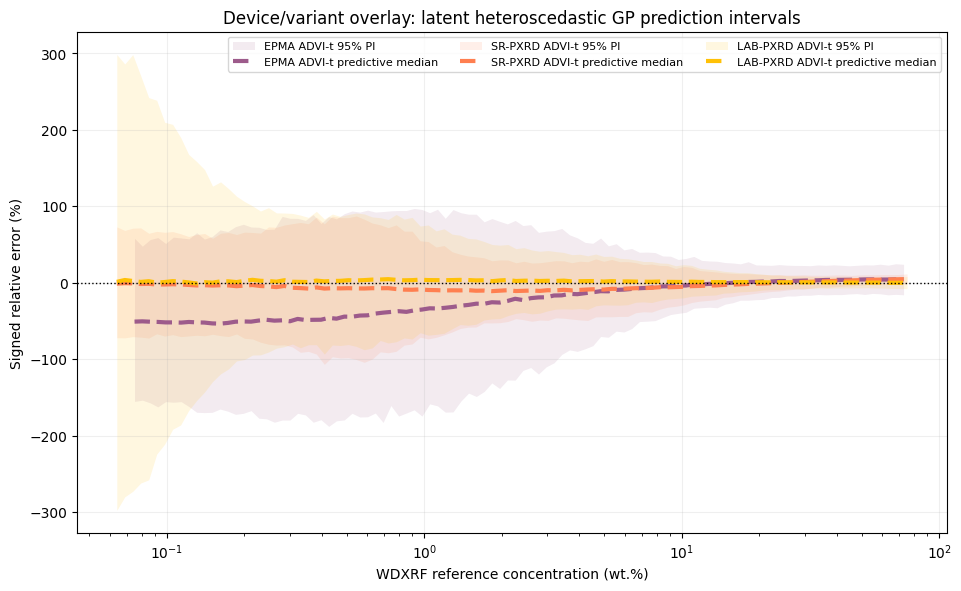

In [5]:
def plot_device_overlay_prediction(predictions_by_device, save_path_png=None, save_path_pdf=None):
    fig, ax = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)

    for label in OVERLAY_DEVICES:
        if label not in predictions_by_device:
            continue

        meta = get_variant_meta(label)
        pred_i = predictions_by_device[label].sort_values("ref_wt")
        color = BASE_DEVICE_COLORS.get(meta["base_device"], "C0")
        linestyle = VARIANT_LINESTYLES.get(meta["variant"], "-")
        alpha = VARIANT_ALPHA.get(meta["variant"], 0.14)

        if PLOT_95_INTERVAL:
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower95"],
                pred_i["pred_error_upper95"],
                color=color,
                alpha=alpha,
                linewidth=0,
                label=f"{label} 95% PI",
            )

        if PLOT_50_INTERVAL and {"pred_error_lower50", "pred_error_upper50"}.issubset(pred_i.columns):
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower50"],
                pred_i["pred_error_upper50"],
                color=color,
                alpha=min(alpha + 0.12, 0.35),
                linewidth=0,
                label=f"{label} 50% PI",
            )

        if PLOT_PREDICTIVE_MEDIAN:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["pred_error_median"],
                color=color,
                linestyle=linestyle,
                linewidth=5 if meta["variant"] == "MCMC Normal" else 3,
                label=f"{label} predictive median",
                solid_capstyle="round",
            )

        if PLOT_MEAN_ERROR:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["mean_error_median"],
                color=color,
                linestyle=linestyle,
                linewidth=1.7,
                alpha=0.9,
                label=f"{label} mean error",
            )

    ax.axhline(0, color="black", linestyle=":", linewidth=1)
    ax.set_xscale("log")
    ax.set_xlabel("WDXRF reference concentration (wt.%)")
    ax.set_ylabel("Signed relative error (%)")
    ax.set_title("Device/variant overlay: latent heteroscedastic GP prediction intervals")
    ax.grid(True, which="major", alpha=0.2)
    ax.legend(ncol=3, fontsize=8)

    if save_path_png is not None:
        save_path_png = Path(save_path_png)
        save_path_png.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_png, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path_png}")

    if save_path_pdf is not None:
        save_path_pdf = Path(save_path_pdf)
        save_path_pdf.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_pdf, bbox_inches="tight")
        print(f"Saved: {save_path_pdf}")

    plt.show()


plot_device_overlay_prediction(
    predictions_by_device,
    save_path_png=FIGURE_DIR / f"{OUTPUT_PREFIX}_prediction_interval.png",
    save_path_pdf=FIGURE_DIR / f"{OUTPUT_PREFIX}_prediction_interval.pdf",
)


## 5. Overlay Plot with data

保存済みの `model_data_{device}.csv` を読み込み、予測区間に観測点を重ねて表示します。存在しない装置のデータはスキップします。

Loaded observed/model-data base devices: ['EPMA', 'SR-PXRD', 'LAB-PXRD']


,base_device,n_data,x_min,x_max,error_min,error_max
0,EPMA,80,0.075,72.733,-96.612827,43.416598
1,SR-PXRD,480,0.064,75.060,-78.614760,97.093683
2,LAB-PXRD,480,0.064,75.060,-100.000000,437.333293


Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/0_device_overlay_ADVI_compare_prediction_interval_with_data_.png
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/0_device_overlay_ADVI_compare_prediction_interval_with_data_.pdf


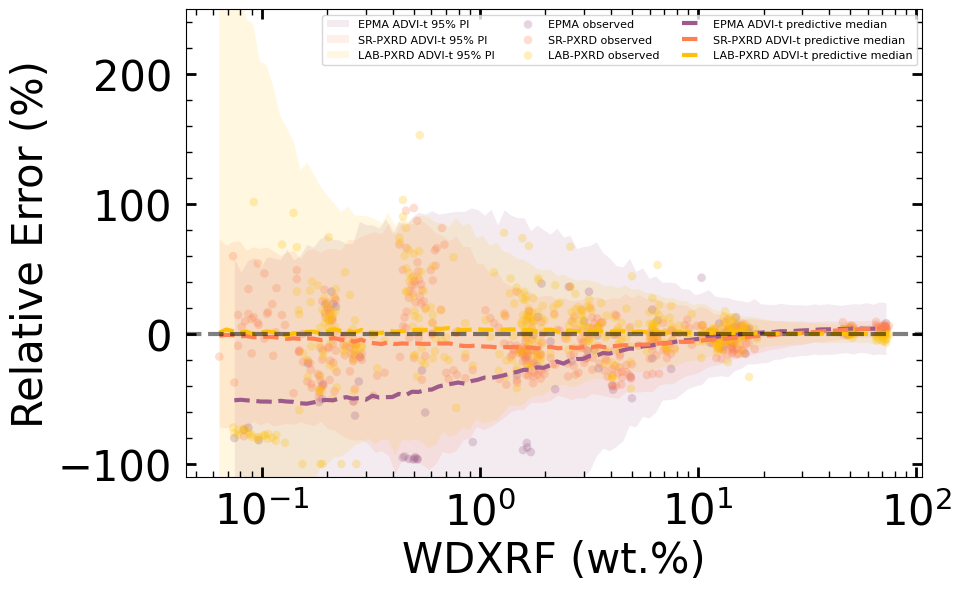

In [6]:
def model_data_path_for_base_device(output_dir, base_device):
    # Prefer ordinary MCMC/Normal model-data as observed data, because observed rows are shared by variants.
    return output_dir / f"one_device_latent_hgp_real_data_model_data_{safe_name(base_device)}.csv"


def load_device_model_data(output_dir, base_devices):
    model_data = {}
    missing = []

    for base_device in base_devices:
        path = model_data_path_for_base_device(output_dir, base_device)
        if not path.exists():
            missing.append((base_device, path))
            continue

        data_i = pd.read_csv(path)
        if "device" not in data_i.columns:
            data_i.insert(0, "device", base_device)
        model_data[base_device] = data_i

    print("Loaded observed/model-data base devices:", list(model_data.keys()))
    if missing:
        print("Missing model data CSVs:")
        for base_device, path in missing:
            print(f"  {base_device}: {path}")

    return model_data


model_data_by_device = load_device_model_data(OUTPUT_DIR, OBSERVED_BASE_DEVICES)

model_data_summary = []
for base_device, data_i in model_data_by_device.items():
    model_data_summary.append({
        "base_device": base_device,
        "n_data": len(data_i),
        "x_min": data_i["ref_wt"].min(),
        "x_max": data_i["ref_wt"].max(),
        "error_min": data_i["error"].min(),
        "error_max": data_i["error"].max(),
    })

model_data_summary_df = pd.DataFrame(model_data_summary)
display(model_data_summary_df)


def plot_device_overlay_prediction_with_data(
    predictions_by_device,
    model_data_by_device,
    save_path_png=None,
    save_path_pdf=None,
    ylim=(-110, 250),
):
    fig, ax = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)

    # Draw intervals first so observed points stay visible.
    for label in OVERLAY_DEVICES:
        if label not in predictions_by_device:
            continue

        meta = get_variant_meta(label)
        pred_i = predictions_by_device[label].sort_values("ref_wt")
        color = BASE_DEVICE_COLORS.get(meta["base_device"], "C0")
        linestyle = VARIANT_LINESTYLES.get(meta["variant"], "-")
        alpha = VARIANT_ALPHA.get(meta["variant"], 0.12)

        if PLOT_95_INTERVAL:
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower95"],
                pred_i["pred_error_upper95"],
                color=color,
                alpha=alpha,
                linewidth=0,
                label=f"{label} 95% PI",
            )

        if PLOT_50_INTERVAL and {"pred_error_lower50", "pred_error_upper50"}.issubset(pred_i.columns):
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower50"],
                pred_i["pred_error_upper50"],
                color=color,
                alpha=min(alpha + 0.12, 0.35),
                linewidth=0,
                label=f"{label} 50% PI",
            )

    # Observations are shown once per base device, not once per variant.
    for base_device in OBSERVED_BASE_DEVICES:
        if base_device not in model_data_by_device:
            continue

        data_i = model_data_by_device[base_device]
        color = BASE_DEVICE_COLORS.get(base_device, "C0")

        ax.scatter(
            data_i["ref_wt"],
            data_i["error"],
            color=color,
            s=38,
            alpha=0.26,
            edgecolor="none",
            label=f"{base_device} observed",
        )

    for label in OVERLAY_DEVICES:
        if label not in predictions_by_device:
            continue

        meta = get_variant_meta(label)
        pred_i = predictions_by_device[label].sort_values("ref_wt")
        color = BASE_DEVICE_COLORS.get(meta["base_device"], "C0")
        linestyle = VARIANT_LINESTYLES.get(meta["variant"], "-")

        if PLOT_PREDICTIVE_MEDIAN:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["pred_error_median"],
                color=color,
                linestyle=linestyle,
                linewidth=5 if meta["variant"] == "MCMC Normal" else 3,
                label=f"{label} predictive median",
                solid_capstyle="round",
            )

        if PLOT_MEAN_ERROR:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["mean_error_median"],
                color=color,
                linestyle=linestyle,
                linewidth=1.7,
                alpha=0.9,
                label=f"{label} mean error",
            )

    ax.axhline(0, color="black", linestyle="--", linewidth=3, alpha=0.5)
    ax.set_xscale("log")
    ax.set_xlabel("WDXRF (wt.%)", fontsize=30)
    ax.set_ylabel("Relative Error (%)", fontsize=30)
    ax.legend(ncol=3, fontsize=8)
    ax.tick_params(which="both", direction="in", bottom=True, left=True, top=True, right=True, labelsize=30, pad=10)
    ax.tick_params(which="major", length=7.5, width=2)
    ax.tick_params(which="minor", length=4, width=1)
    ax.set_ylim(*ylim)

    ax.yaxis.set_major_locator(MultipleLocator(100))
    ax.yaxis.set_minor_locator(MultipleLocator(20))

    if save_path_png is not None:
        save_path_png = Path(save_path_png)
        save_path_png.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_png, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path_png}")

    if save_path_pdf is not None:
        save_path_pdf = Path(save_path_pdf)
        save_path_pdf.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_pdf, bbox_inches="tight")
        print(f"Saved: {save_path_pdf}")

    plt.show()


plot_device_overlay_prediction_with_data(
    predictions_by_device,
    model_data_by_device,
    save_path_png=FIGURE_DIR / f"0_{OUTPUT_PREFIX}_prediction_interval_with_data_.png",
    save_path_pdf=FIGURE_DIR / f"0_{OUTPUT_PREFIX}_prediction_interval_with_data_.pdf",
    ylim=(-110, 250),
)


Loaded observed/model-data base devices: ['EPMA', 'SR-PXRD', 'LAB-PXRD']


,base_device,n_data,x_min,x_max,error_min,error_max
0,EPMA,80,0.075,72.733,-96.612827,43.416598
1,SR-PXRD,480,0.064,75.060,-78.614760,97.093683
2,LAB-PXRD,480,0.064,75.060,-100.000000,437.333293


Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/0_device_overlay_ADVI_compare_prediction_interval_with_data.png
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/0_device_overlay_ADVI_compare_prediction_interval_with_data.pdf


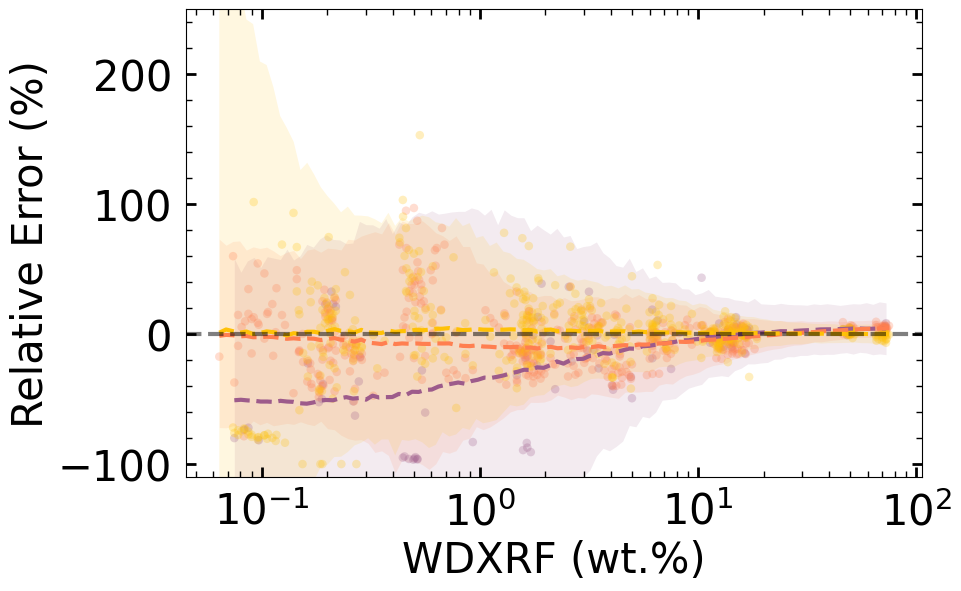

In [7]:
def model_data_path_for_base_device(output_dir, base_device):
    # Prefer ordinary MCMC/Normal model-data as observed data, because observed rows are shared by variants.
    return output_dir / f"one_device_latent_hgp_real_data_model_data_{safe_name(base_device)}.csv"


def load_device_model_data(output_dir, base_devices):
    model_data = {}
    missing = []

    for base_device in base_devices:
        path = model_data_path_for_base_device(output_dir, base_device)
        if not path.exists():
            missing.append((base_device, path))
            continue

        data_i = pd.read_csv(path)
        if "device" not in data_i.columns:
            data_i.insert(0, "device", base_device)
        model_data[base_device] = data_i

    print("Loaded observed/model-data base devices:", list(model_data.keys()))
    if missing:
        print("Missing model data CSVs:")
        for base_device, path in missing:
            print(f"  {base_device}: {path}")

    return model_data


model_data_by_device = load_device_model_data(OUTPUT_DIR, OBSERVED_BASE_DEVICES)

model_data_summary = []
for base_device, data_i in model_data_by_device.items():
    model_data_summary.append({
        "base_device": base_device,
        "n_data": len(data_i),
        "x_min": data_i["ref_wt"].min(),
        "x_max": data_i["ref_wt"].max(),
        "error_min": data_i["error"].min(),
        "error_max": data_i["error"].max(),
    })

model_data_summary_df = pd.DataFrame(model_data_summary)
display(model_data_summary_df)


def plot_device_overlay_prediction_with_data(
    predictions_by_device,
    model_data_by_device,
    save_path_png=None,
    save_path_pdf=None,
    ylim=(-110, 250),
):
    fig, ax = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)

    # Draw intervals first so observed points stay visible.
    for label in OVERLAY_DEVICES:
        if label not in predictions_by_device:
            continue

        meta = get_variant_meta(label)
        pred_i = predictions_by_device[label].sort_values("ref_wt")
        color = BASE_DEVICE_COLORS.get(meta["base_device"], "C0")
        linestyle = VARIANT_LINESTYLES.get(meta["variant"], "-")
        alpha = VARIANT_ALPHA.get(meta["variant"], 0.12)

        if PLOT_95_INTERVAL:
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower95"],
                pred_i["pred_error_upper95"],
                color=color,
                alpha=alpha,
                linewidth=0,
                label=f"{label} 95% PI",
            )

        if PLOT_50_INTERVAL and {"pred_error_lower50", "pred_error_upper50"}.issubset(pred_i.columns):
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower50"],
                pred_i["pred_error_upper50"],
                color=color,
                alpha=min(alpha + 0.12, 0.35),
                linewidth=0,
                label=f"{label} 50% PI",
            )

    # Observations are shown once per base device, not once per variant.
    for base_device in OBSERVED_BASE_DEVICES:
        if base_device not in model_data_by_device:
            continue

        data_i = model_data_by_device[base_device]
        color = BASE_DEVICE_COLORS.get(base_device, "C0")

        ax.scatter(
            data_i["ref_wt"],
            data_i["error"],
            color=color,
            s=38,
            alpha=0.26,
            edgecolor="none",
            label=f"{base_device} observed",
        )

    for label in OVERLAY_DEVICES:
        if label not in predictions_by_device:
            continue

        meta = get_variant_meta(label)
        pred_i = predictions_by_device[label].sort_values("ref_wt")
        color = BASE_DEVICE_COLORS.get(meta["base_device"], "C0")
        linestyle = VARIANT_LINESTYLES.get(meta["variant"], "-")

        if PLOT_PREDICTIVE_MEDIAN:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["pred_error_median"],
                color=color,
                linestyle=linestyle,
                linewidth=5 if meta["variant"] == "MCMC Normal" else 3,
                label=f"{label} predictive median",
                solid_capstyle="round",
            )

        if PLOT_MEAN_ERROR:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["mean_error_median"],
                color=color,
                linestyle=linestyle,
                linewidth=1.7,
                alpha=0.9,
                label=f"{label} mean error",
            )

    ax.axhline(0, color="black", linestyle="--", linewidth=3, alpha=0.5)
    ax.set_xscale("log")
    ax.set_xlabel("WDXRF (wt.%)", fontsize=30)
    ax.set_ylabel("Relative Error (%)", fontsize=30)
    # ax.legend(ncol=2, fontsize=8)
    ax.tick_params(which="both", direction="in", bottom=True, left=True, top=True, right=True, labelsize=30, pad=10)
    ax.tick_params(which="major", length=7.5, width=2)
    ax.tick_params(which="minor", length=4, width=1)
    ax.set_ylim(*ylim)

    ax.yaxis.set_major_locator(MultipleLocator(100))
    ax.yaxis.set_minor_locator(MultipleLocator(20))

    if save_path_png is not None:
        save_path_png = Path(save_path_png)
        save_path_png.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_png, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path_png}")

    if save_path_pdf is not None:
        save_path_pdf = Path(save_path_pdf)
        save_path_pdf.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_pdf, bbox_inches="tight")
        print(f"Saved: {save_path_pdf}")

    plt.show()


plot_device_overlay_prediction_with_data(
    predictions_by_device,
    model_data_by_device,
    save_path_png=FIGURE_DIR / f"0_{OUTPUT_PREFIX}_prediction_interval_with_data.png",
    save_path_pdf=FIGURE_DIR / f"0_{OUTPUT_PREFIX}_prediction_interval_with_data.pdf",
    ylim=(-110, 250),
)


In [8]:
def predict_one_device_latent_heteroscedastic_gp(
    model,
    idata,
    meta,
    gp_objects,
    x_grid_raw,
    pred_suffix="v1",
    random_seed=123,
):
    """
    予測グリッド上で、平均誤差、標準偏差、次回errorの予測区間を計算する。

    Notes
    -----
    この関数は model に f_pred_{suffix}, h_raw_pred_{suffix} を追加する。
    同じモデルで何度も呼ぶ場合は、pred_suffix を変えてください。
    """

    rng = np.random.default_rng(random_seed)

    x_grid_raw = np.asarray(x_grid_raw, dtype=float)

    x_grid_scaled = transform_x_new(
        x_grid_raw,
        meta["transform_meta"],
    )

    Xnew = x_grid_scaled[:, None]

    gp_f = gp_objects["gp_f"]
    gp_h = gp_objects["gp_h"]

    f_name = f"f_pred_{pred_suffix}"
    h_name = f"h_raw_pred_{pred_suffix}"

    with model:
        # 予測点での平均GP
        f_pred = gp_f.conditional(
            f_name,
            Xnew=Xnew,
        )

        # 予測点でのlog_sigmaのraw GP成分
        h_raw_pred = gp_h.conditional(
            h_name,
            Xnew=Xnew,
        )

        ppc = pm.sample_posterior_predictive(
            idata,
            var_names=[f_name, h_name],
            random_seed=random_seed,
            return_inferencedata=True,
        )

    # shape: chain, draw, n_grid
    f_arr = ppc.posterior_predictive[f_name].values
    h_raw_arr = ppc.posterior_predictive[h_name].values

    # h0 はposteriorから取り出す
    h0_arr = idata.posterior["h0"].values  # chain, draw

    # log_sigma = h0 + h_raw
    log_sigma_arr = h0_arr[:, :, None] + h_raw_arr

    sigma_arr = np.exp(log_sigma_arr)

    # 次回errorを生成
    # e_new_arr = rng.normal(
    #     loc=f_arr,
    #     scale=sigma_arr,
    # )

    e_new_arr = (
        f_arr
        + sigma_arr
        * rng.standard_t(
            df=meta["student_t_nu"],
            size=f_arr.shape,
        )
    )

    # chain, draw をsample軸にまとめる
    n_chain, n_draw, n_grid = f_arr.shape

    f_flat = f_arr.reshape(n_chain * n_draw, n_grid)
    sigma_flat = sigma_arr.reshape(n_chain * n_draw, n_grid)
    e_new_flat = e_new_arr.reshape(n_chain * n_draw, n_grid)

    result = pd.DataFrame({
        "ref_wt": x_grid_raw,

        # 平均誤差関数 f(x)
        "mean_error_median": np.quantile(f_flat, 0.50, axis=0),
        "mean_error_lower95": np.quantile(f_flat, 0.025, axis=0),
        "mean_error_upper95": np.quantile(f_flat, 0.975, axis=0),

        # 標準偏差 sigma(x)
        "sigma_median": np.quantile(sigma_flat, 0.50, axis=0),
        "sigma_lower95": np.quantile(sigma_flat, 0.025, axis=0),
        "sigma_upper95": np.quantile(sigma_flat, 0.975, axis=0),

        # 次回errorの予測分布
        "pred_error_median": np.quantile(e_new_flat, 0.50, axis=0),
        "pred_error_lower50": np.quantile(e_new_flat, 0.25, axis=0),
        "pred_error_upper50": np.quantile(e_new_flat, 0.75, axis=0),
        "pred_error_lower90": np.quantile(e_new_flat, 0.05, axis=0),
        "pred_error_upper90": np.quantile(e_new_flat, 0.95, axis=0),
        "pred_error_lower95": np.quantile(e_new_flat, 0.025, axis=0),
        "pred_error_upper95": np.quantile(e_new_flat, 0.975, axis=0),
    })

    return result


In [9]:
def predict_one_device_latent_heteroscedastic_gp(
    model,
    idata,
    meta,
    gp_objects,
    x_grid_raw,
    pred_suffix="v1",
    random_seed=123,
):
    """
    予測グリッド上で、平均誤差、標準偏差、次回errorの予測区間を計算する。

    Notes
    -----
    この関数は model に f_pred_{suffix}, h_raw_pred_{suffix} を追加する。
    同じモデルで何度も呼ぶ場合は、pred_suffix を変えてください。
    """

    rng = np.random.default_rng(random_seed)

    x_grid_raw = np.asarray(x_grid_raw, dtype=float)

    x_grid_scaled = transform_x_new(
        x_grid_raw,
        meta["transform_meta"],
    )

    Xnew = x_grid_scaled[:, None]

    gp_f = gp_objects["gp_f"]
    gp_h = gp_objects["gp_h"]

    f_name = f"f_pred_{pred_suffix}"
    h_name = f"h_raw_pred_{pred_suffix}"

    with model:
        # 予測点での平均GP
        f_pred = gp_f.conditional(
            f_name,
            Xnew=Xnew,
        )

        # 予測点でのlog_sigmaのraw GP成分
        h_raw_pred = gp_h.conditional(
            h_name,
            Xnew=Xnew,
        )

        ppc = pm.sample_posterior_predictive(
            idata,
            var_names=[f_name, h_name],
            random_seed=random_seed,
            return_inferencedata=True,
        )

    # shape: chain, draw, n_grid
    f_arr = ppc.posterior_predictive[f_name].values
    h_raw_arr = ppc.posterior_predictive[h_name].values

    # h0 はposteriorから取り出す
    h0_arr = idata.posterior["h0"].values  # chain, draw

    # log_sigma = h0 + h_raw
    log_sigma_arr = h0_arr[:, :, None] + h_raw_arr

    sigma_arr = np.exp(log_sigma_arr)

    # 次回errorを生成
    # e_new_arr = rng.normal(
    #     loc=f_arr,
    #     scale=sigma_arr,
    # )

    e_new_arr = (
        f_arr
        + sigma_arr
        * rng.standard_t(
            df=meta["student_t_nu"],
            size=f_arr.shape,
        )
    )

    # chain, draw をsample軸にまとめる
    n_chain, n_draw, n_grid = f_arr.shape

    f_flat = f_arr.reshape(n_chain * n_draw, n_grid)
    sigma_flat = sigma_arr.reshape(n_chain * n_draw, n_grid)
    e_new_flat = e_new_arr.reshape(n_chain * n_draw, n_grid)

    result = pd.DataFrame({
        "ref_wt": x_grid_raw,

        # 平均誤差関数 f(x)
        "mean_error_median": np.quantile(f_flat, 0.50, axis=0),
        "mean_error_lower95": np.quantile(f_flat, 0.025, axis=0),
        "mean_error_upper95": np.quantile(f_flat, 0.975, axis=0),

        # 標準偏差 sigma(x)
        "sigma_median": np.quantile(sigma_flat, 0.50, axis=0),
        "sigma_lower95": np.quantile(sigma_flat, 0.025, axis=0),
        "sigma_upper95": np.quantile(sigma_flat, 0.975, axis=0),

        # 次回errorの予測分布
        "pred_error_median": np.quantile(e_new_flat, 0.50, axis=0),
        "pred_error_lower50": np.quantile(e_new_flat, 0.25, axis=0),
        "pred_error_upper50": np.quantile(e_new_flat, 0.75, axis=0),
        "pred_error_lower90": np.quantile(e_new_flat, 0.05, axis=0),
        "pred_error_upper90": np.quantile(e_new_flat, 0.95, axis=0),
        "pred_error_lower95": np.quantile(e_new_flat, 0.025, axis=0),
        "pred_error_upper95": np.quantile(e_new_flat, 0.975, axis=0),
    })

    return result


Loaded observed/model-data base devices: ['EPMA', 'SR-PXRD', 'LAB-PXRD']


,base_device,n_data,x_min,x_max,error_min,error_max
0,EPMA,80,0.075,72.733,-96.612827,43.416598
1,SR-PXRD,480,0.064,75.060,-78.614760,97.093683
2,LAB-PXRD,480,0.064,75.060,-100.000000,437.333293


Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/0_device_overlay_ADVI_compare_prediction_interval_with_data_all.png
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/0_device_overlay_ADVI_compare_prediction_interval_with_data_all.pdf


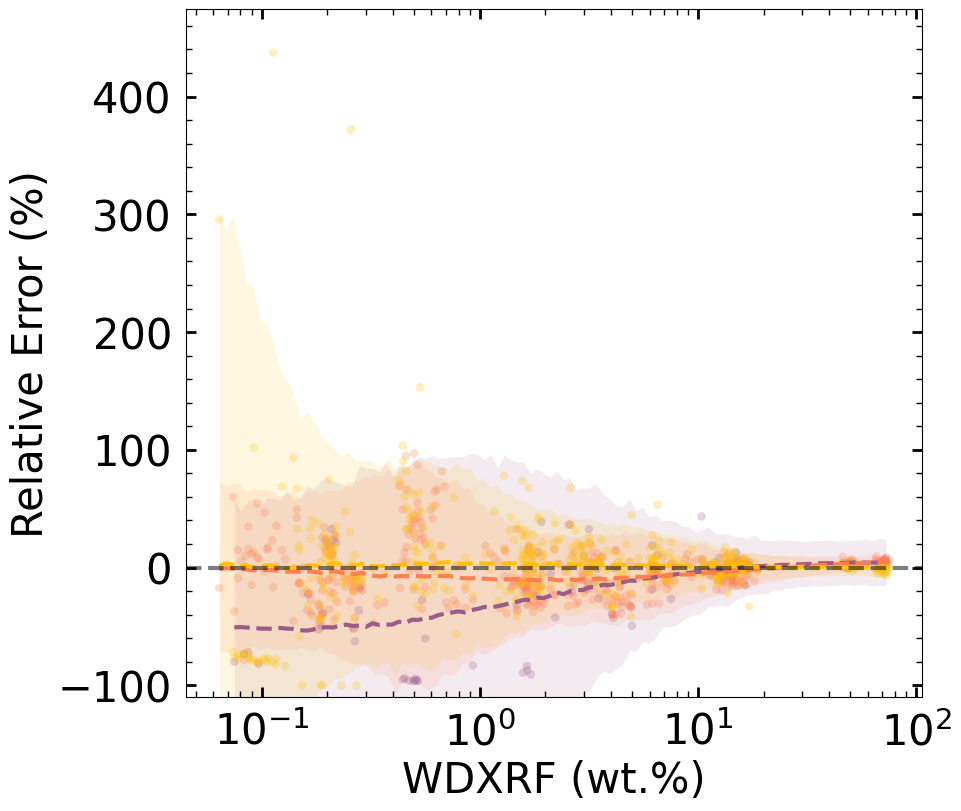

In [10]:
def model_data_path_for_base_device(output_dir, base_device):
    # Prefer ordinary MCMC/Normal model-data as observed data, because observed rows are shared by variants.
    return output_dir / f"one_device_latent_hgp_real_data_model_data_{safe_name(base_device)}.csv"


def load_device_model_data(output_dir, base_devices):
    model_data = {}
    missing = []

    for base_device in base_devices:
        path = model_data_path_for_base_device(output_dir, base_device)
        if not path.exists():
            missing.append((base_device, path))
            continue

        data_i = pd.read_csv(path)
        if "device" not in data_i.columns:
            data_i.insert(0, "device", base_device)
        model_data[base_device] = data_i

    print("Loaded observed/model-data base devices:", list(model_data.keys()))
    if missing:
        print("Missing model data CSVs:")
        for base_device, path in missing:
            print(f"  {base_device}: {path}")

    return model_data


model_data_by_device = load_device_model_data(OUTPUT_DIR, OBSERVED_BASE_DEVICES)

model_data_summary = []
for base_device, data_i in model_data_by_device.items():
    model_data_summary.append({
        "base_device": base_device,
        "n_data": len(data_i),
        "x_min": data_i["ref_wt"].min(),
        "x_max": data_i["ref_wt"].max(),
        "error_min": data_i["error"].min(),
        "error_max": data_i["error"].max(),
    })

model_data_summary_df = pd.DataFrame(model_data_summary)
display(model_data_summary_df)


def plot_device_overlay_prediction_with_data(
    predictions_by_device,
    model_data_by_device,
    save_path_png=None,
    save_path_pdf=None,
    ylim=(-110, 250),
):
    # fig, ax = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)
    fig, ax = plt.subplots(figsize=(9.5, 8), constrained_layout=True)

    # Draw intervals first so observed points stay visible.
    for label in OVERLAY_DEVICES:
        if label not in predictions_by_device:
            continue

        meta = get_variant_meta(label)
        pred_i = predictions_by_device[label].sort_values("ref_wt")
        color = BASE_DEVICE_COLORS.get(meta["base_device"], "C0")
        linestyle = VARIANT_LINESTYLES.get(meta["variant"], "-")
        alpha = VARIANT_ALPHA.get(meta["variant"], 0.12)

        if PLOT_95_INTERVAL:
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower95"],
                pred_i["pred_error_upper95"],
                color=color,
                alpha=alpha,
                linewidth=0,
                label=f"{label} 95% PI",
            )

        if PLOT_50_INTERVAL and {"pred_error_lower50", "pred_error_upper50"}.issubset(pred_i.columns):
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower50"],
                pred_i["pred_error_upper50"],
                color=color,
                alpha=min(alpha + 0.12, 0.35),
                linewidth=0,
                label=f"{label} 50% PI",
            )

    # Observations are shown once per base device, not once per variant.
    for base_device in OBSERVED_BASE_DEVICES:
        if base_device not in model_data_by_device:
            continue

        data_i = model_data_by_device[base_device]
        color = BASE_DEVICE_COLORS.get(base_device, "C0")

        ax.scatter(
            data_i["ref_wt"],
            data_i["error"],
            color=color,
            s=38,
            alpha=0.26,
            edgecolor="none",
            label=f"{base_device} observed",
        )

    for label in OVERLAY_DEVICES:
        if label not in predictions_by_device:
            continue

        meta = get_variant_meta(label)
        pred_i = predictions_by_device[label].sort_values("ref_wt")
        color = BASE_DEVICE_COLORS.get(meta["base_device"], "C0")
        linestyle = VARIANT_LINESTYLES.get(meta["variant"], "-")

        if PLOT_PREDICTIVE_MEDIAN:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["pred_error_median"],
                color=color,
                linestyle=linestyle,
                linewidth=5 if meta["variant"] == "MCMC Normal" else 3,
                label=f"{label} predictive median",
                solid_capstyle="round",
            )

        if PLOT_MEAN_ERROR:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["mean_error_median"],
                color=color,
                linestyle=linestyle,
                linewidth=1.7,
                alpha=0.9,
                label=f"{label} mean error",
            )

    ax.axhline(0, color="black", linestyle="--", linewidth=3, alpha=0.5)
    ax.set_xscale("log")
    ax.set_xlabel("WDXRF (wt.%)", fontsize=30)
    ax.set_ylabel("Relative Error (%)", fontsize=30)
    # ax.legend(ncol=2, fontsize=8)
    ax.tick_params(which="both", direction="in", bottom=True, left=True, top=True, right=True, labelsize=30, pad=10)
    ax.tick_params(which="major", length=7.5, width=2)
    ax.tick_params(which="minor", length=4, width=1)
    ax.set_ylim(*ylim)

    ax.yaxis.set_major_locator(MultipleLocator(100))
    ax.yaxis.set_minor_locator(MultipleLocator(20))

    if save_path_png is not None:
        save_path_png = Path(save_path_png)
        save_path_png.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_png, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path_png}")

    if save_path_pdf is not None:
        save_path_pdf = Path(save_path_pdf)
        save_path_pdf.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_pdf, bbox_inches="tight")
        print(f"Saved: {save_path_pdf}")

    plt.show()


plot_device_overlay_prediction_with_data(
    predictions_by_device,
    model_data_by_device,
    save_path_png=FIGURE_DIR / f"0_{OUTPUT_PREFIX}_prediction_interval_with_data_all.png",
    save_path_pdf=FIGURE_DIR / f"0_{OUTPUT_PREFIX}_prediction_interval_with_data_all.pdf",
    ylim=(-110, None),
)


## 6. Overlay Estimated Heteroscedasticity / Scale

装置・推論variantごとの `sigma_median`, `sigma_lower95`, `sigma_upper95` を重ねて比較します。Student-t版の `sigma` は標準偏差ではなくscale parameterです。


All loaded prediction tables have required sigma columns.
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/0_device_overlay_ADVI_compare_estimated_heteroscedasticity_.png
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/0_device_overlay_ADVI_compare_estimated_heteroscedasticity_.pdf


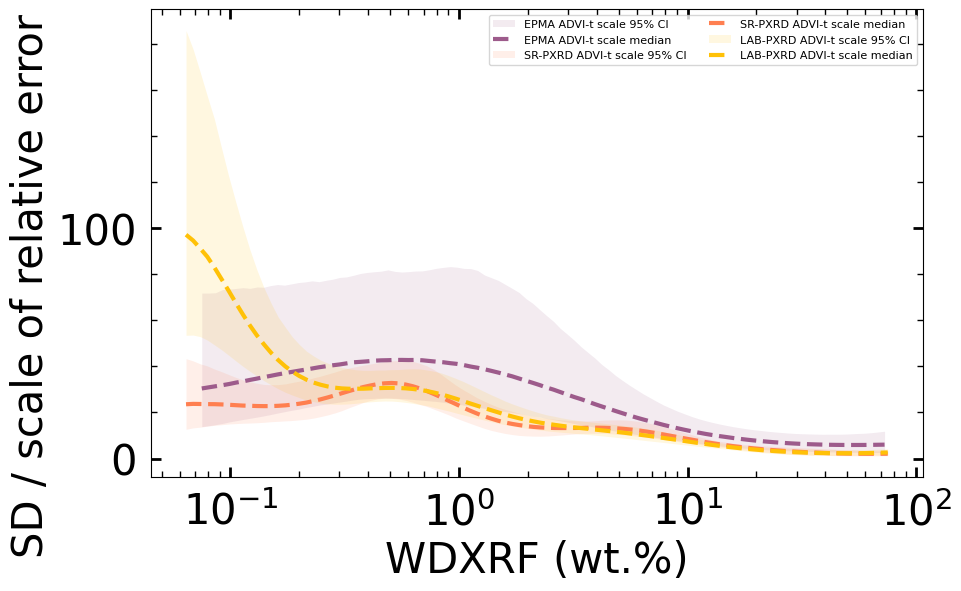

In [11]:
SIGMA_REQUIRED_COLUMNS = [
    "ref_wt",
    "sigma_median",
    "sigma_lower95",
    "sigma_upper95",
]

for label, pred_i in predictions_by_device.items():
    missing_cols = [col for col in SIGMA_REQUIRED_COLUMNS if col not in pred_i.columns]
    if missing_cols:
        raise ValueError(f"{label} is missing required sigma columns: {missing_cols}")

print("All loaded prediction tables have required sigma columns.")


def plot_device_overlay_sigma(
    predictions_by_device,
    save_path_png=None,
    save_path_pdf=None,
):
    fig, ax = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)

    for label in OVERLAY_DEVICES:
        if label not in predictions_by_device:
            continue

        meta = get_variant_meta(label)
        pred_i = predictions_by_device[label].sort_values("ref_wt")
        color = BASE_DEVICE_COLORS.get(meta["base_device"], "C0")
        linestyle = VARIANT_LINESTYLES.get(meta["variant"], "-")
        alpha = VARIANT_ALPHA.get(meta["variant"], 0.14)
        scale_label = "scale" if "Student-t" in meta["variant"] else "sigma"

        ax.fill_between(
            pred_i["ref_wt"],
            pred_i["sigma_lower95"],
            pred_i["sigma_upper95"],
            color=color,
            alpha=alpha,
            linewidth=0,
            label=f"{label} {scale_label} 95% CI",
        )

        ax.plot(
            pred_i["ref_wt"],
            pred_i["sigma_median"],
            color=color,
            linestyle=linestyle,
            linewidth=5 if meta["variant"] == "MCMC Normal" else 3,
            label=f"{label} {scale_label} median",
            solid_capstyle="round",
        )

    ax.set_xscale("log")
    ax.set_xlabel("WDXRF (wt.%)", fontsize=30)
    ax.set_ylabel("SD / scale of relative error (%)", fontsize=30)
    ax.legend(ncol=2, fontsize=8)
    ax.tick_params(which="both", direction="in", bottom=True, left=True, top=True, right=True, labelsize=30, pad=10)
    ax.tick_params(which="major", length=7.5, width=2)
    ax.tick_params(which="minor", length=4, width=1)

    ax.yaxis.set_major_locator(MultipleLocator(100))
    ax.yaxis.set_minor_locator(MultipleLocator(20))

    if save_path_png is not None:
        save_path_png = Path(save_path_png)
        save_path_png.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_png, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path_png}")

    if save_path_pdf is not None:
        save_path_pdf = Path(save_path_pdf)
        save_path_pdf.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_pdf, bbox_inches="tight")
        print(f"Saved: {save_path_pdf}")

    plt.show()


plot_device_overlay_sigma(
    predictions_by_device,
    save_path_png=FIGURE_DIR / f"0_{OUTPUT_PREFIX}_estimated_heteroscedasticity_.png",
    save_path_pdf=FIGURE_DIR / f"0_{OUTPUT_PREFIX}_estimated_heteroscedasticity_.pdf",
)


All loaded prediction tables have required sigma columns.
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/0_device_overlay_ADVI_compare_estimated_heteroscedasticity.png
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/0_device_overlay_ADVI_compare_estimated_heteroscedasticity.pdf


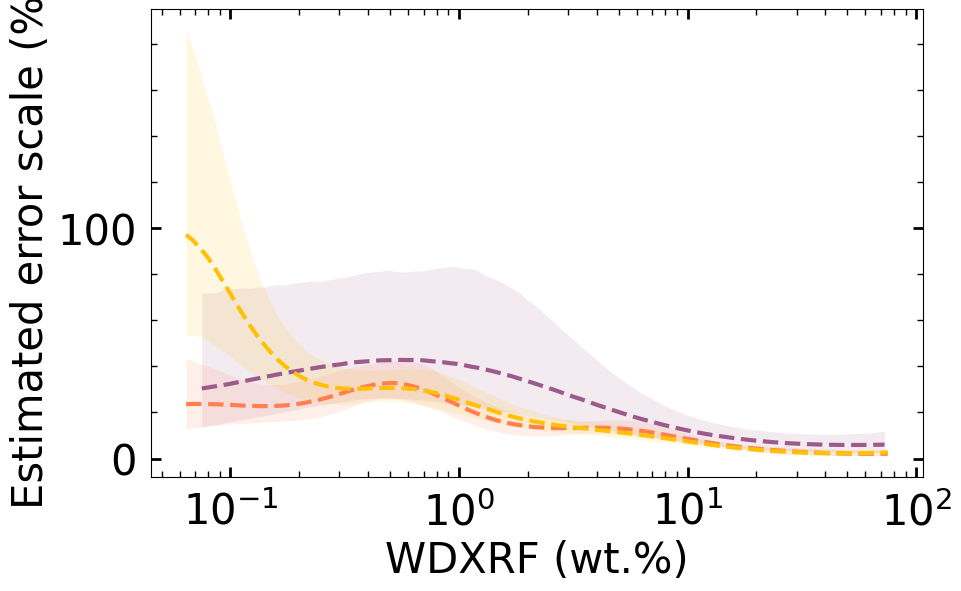

In [12]:
SIGMA_REQUIRED_COLUMNS = [
    "ref_wt",
    "sigma_median",
    "sigma_lower95",
    "sigma_upper95",
]

for label, pred_i in predictions_by_device.items():
    missing_cols = [col for col in SIGMA_REQUIRED_COLUMNS if col not in pred_i.columns]
    if missing_cols:
        raise ValueError(f"{label} is missing required sigma columns: {missing_cols}")

print("All loaded prediction tables have required sigma columns.")


def plot_device_overlay_sigma(
    predictions_by_device,
    save_path_png=None,
    save_path_pdf=None,
):
    fig, ax = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)

    for label in OVERLAY_DEVICES:
        if label not in predictions_by_device:
            continue

        meta = get_variant_meta(label)
        pred_i = predictions_by_device[label].sort_values("ref_wt")
        color = BASE_DEVICE_COLORS.get(meta["base_device"], "C0")
        linestyle = VARIANT_LINESTYLES.get(meta["variant"], "-")
        alpha = VARIANT_ALPHA.get(meta["variant"], 0.14)
        scale_label = "scale" if "Student-t" in meta["variant"] else "sigma"

        ax.fill_between(
            pred_i["ref_wt"],
            pred_i["sigma_lower95"],
            pred_i["sigma_upper95"],
            color=color,
            alpha=alpha,
            linewidth=0,
            label=f"{label} {scale_label} 95% CI",
        )

        ax.plot(
            pred_i["ref_wt"],
            pred_i["sigma_median"],
            color=color,
            linestyle=linestyle,
            linewidth=5 if meta["variant"] == "MCMC Normal" else 3,
            label=f"{label} {scale_label} median",
            solid_capstyle="round",
        )

    ax.set_xscale("log")
    ax.set_xlabel("WDXRF (wt.%)", fontsize=30)
    ax.set_ylabel("Estimated error scale (%)", fontsize=30)
    # ax.legend(ncol=2, fontsize=8)
    ax.tick_params(which="both", direction="in", bottom=True, left=True, top=True, right=True, labelsize=30, pad=10)
    ax.tick_params(which="major", length=7.5, width=2)
    ax.tick_params(which="minor", length=4, width=1)

    ax.yaxis.set_major_locator(MultipleLocator(100))
    ax.yaxis.set_minor_locator(MultipleLocator(20))

    if save_path_png is not None:
        save_path_png = Path(save_path_png)
        save_path_png.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_png, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path_png}")

    if save_path_pdf is not None:
        save_path_pdf = Path(save_path_pdf)
        save_path_pdf.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_pdf, bbox_inches="tight")
        print(f"Saved: {save_path_pdf}")

    plt.show()


plot_device_overlay_sigma(
    predictions_by_device,
    save_path_png=FIGURE_DIR / f"0_{OUTPUT_PREFIX}_estimated_heteroscedasticity.png",
    save_path_pdf=FIGURE_DIR / f"0_{OUTPUT_PREFIX}_estimated_heteroscedasticity.pdf",
)


Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_ADVI_compare_estimated_heteroscedasticity_with_observed_error.png
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_ADVI_compare_estimated_heteroscedasticity_with_observed_error.pdf


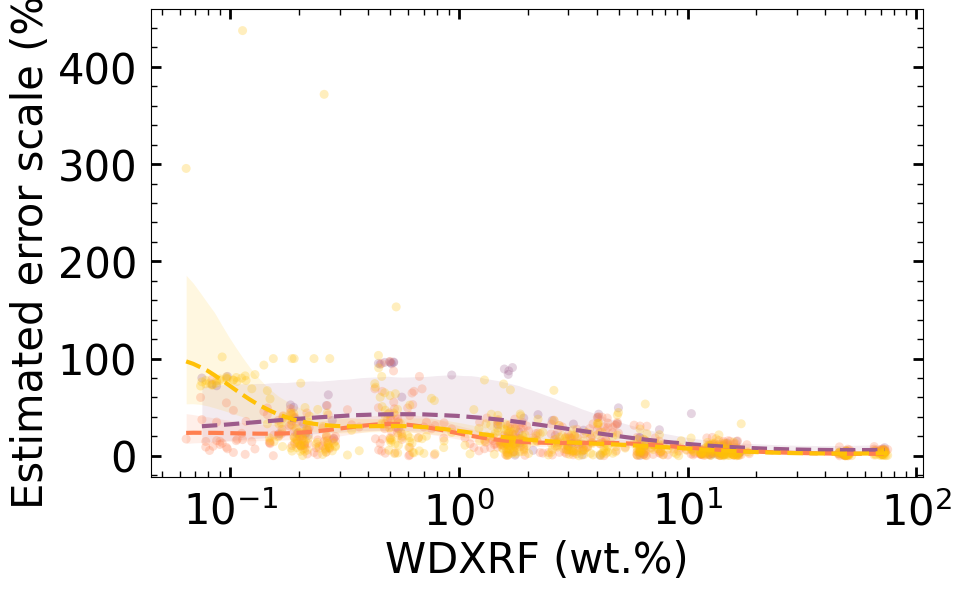

In [13]:
def plot_device_overlay_sigma_with_observed_error(
    predictions_by_device,
    model_data_by_device,
    save_path_png=None,
    save_path_pdf=None,
):
    fig, ax = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)

    for label in OVERLAY_DEVICES:
        if label not in predictions_by_device:
            continue

        meta = get_variant_meta(label)
        pred_i = predictions_by_device[label].sort_values("ref_wt")
        color = BASE_DEVICE_COLORS.get(meta["base_device"], "C0")
        linestyle = VARIANT_LINESTYLES.get(meta["variant"], "-")
        alpha = VARIANT_ALPHA.get(meta["variant"], 0.12)
        scale_label = "scale" if "Student-t" in meta["variant"] else "sigma"

        ax.fill_between(
            pred_i["ref_wt"],
            pred_i["sigma_lower95"],
            pred_i["sigma_upper95"],
            color=color,
            alpha=alpha,
            linewidth=0,
            label=f"{label} {scale_label} 95% CI",
        )

    for base_device in OBSERVED_BASE_DEVICES:
        if base_device not in model_data_by_device:
            continue

        data_i = model_data_by_device[base_device]
        color = BASE_DEVICE_COLORS.get(base_device, "C0")

        ax.scatter(
            data_i["ref_wt"],
            data_i["error"].abs(),
            color=color,
            s=42,
            alpha=0.26,
            edgecolor="none",
            label=f"{base_device} observed |error|",
        )

    for label in OVERLAY_DEVICES:
        if label not in predictions_by_device:
            continue

        meta = get_variant_meta(label)
        pred_i = predictions_by_device[label].sort_values("ref_wt")
        color = BASE_DEVICE_COLORS.get(meta["base_device"], "C0")
        linestyle = VARIANT_LINESTYLES.get(meta["variant"], "-")
        scale_label = "scale" if "Student-t" in meta["variant"] else "sigma"

        ax.plot(
            pred_i["ref_wt"],
            pred_i["sigma_median"],
            color=color,
            linestyle=linestyle,
            linewidth=5 if meta["variant"] == "MCMC Normal" else 3,
            label=f"{label} {scale_label} median",
            solid_capstyle="round",
        )

    ax.set_xscale("log")
    ax.set_xlabel("WDXRF (wt.%)", fontsize=30)
    ax.set_ylabel("Estimated error scale (%)", fontsize=30)
    # ax.legend(ncol=2, fontsize=8)
    ax.tick_params(which="both", direction="in", bottom=True, left=True, top=True, right=True, labelsize=30, pad=10)
    ax.tick_params(which="major", length=7.5, width=2)
    ax.tick_params(which="minor", length=4, width=1)

    ax.yaxis.set_major_locator(MultipleLocator(100))
    ax.yaxis.set_minor_locator(MultipleLocator(20))

    if save_path_png is not None:
        save_path_png = Path(save_path_png)
        save_path_png.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_png, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path_png}")

    if save_path_pdf is not None:
        save_path_pdf = Path(save_path_pdf)
        save_path_pdf.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_pdf, bbox_inches="tight")
        print(f"Saved: {save_path_pdf}")

    plt.show()


plot_device_overlay_sigma_with_observed_error(
    predictions_by_device,
    model_data_by_device,
    save_path_png=FIGURE_DIR / f"{OUTPUT_PREFIX}_estimated_heteroscedasticity_with_observed_error.png",
    save_path_pdf=FIGURE_DIR / f"{OUTPUT_PREFIX}_estimated_heteroscedasticity_with_observed_error.pdf",
)
